In [7]:
import open3d as o3d
import numpy as np
import copy
import time # python的time库，可以计算配准所需的时间
import copy
import sys

### Visualization
source: yellow, target: Blue 同07

In [8]:
#3个参数：源点云、目标点云、4*4变换阵
#变换阵通过global registration得到
def draw_registration_result(source, target, transformation):
    #创建源点云和目标点云的副本，因为后面要染色，直接在原始点云上改的话会修改原始数据
    #用pythond的copy.deepcopy复制，所以一开始要import copy
    source_temp = copy.deepcopy(source)
    target_temp = copy.deepcopy(target)
    #给点云设置颜色
    source_temp.paint_uniform_color([1, 0.706, 0])      #变换后的源点云黄色
    target_temp.paint_uniform_color([0, 0.651, 0.929])  #目标点云青色
    #将源点云副本变换到目标点云的坐标系Initial Registration
    #只变换源点云，不变换目标点云
    source_temp.transform(transformation)
    o3d.visualization.draw_geometries([source_temp, target_temp])

### Extract geometric feature 提取几何特征 FPFH
We downsample the point cloud, estimate normals, then compute a FPFH feature for each point. The FPFH feature is a 33-dimensional vector that describes the local geometric property of a point. A nearest neighbor query in the 33-dimensional space can return points with similar local geometric structures. See [Rasu2009] for details.

我们首先对点云进行下采样，然后估计法向量，接着计算每个点的 FPFH 特征。FPFH 特征是一个 33 维向量，用于描述点的局部几何属性。
通过在这个 33 维特征空间中进行最近邻搜索，可以找到具有相似局部几何结构的点。详细信息请参阅文献 [Rasu2009]

FPFH 的全称是 Fast Point Feature Histograms（快速点特征直方图）。它利用点及其邻域的几何关系，尤其是法向量之间的关系，构造一个 33 维特征向量。

In [9]:
# Voxel下采样 -> 法向量估计Normal Estimation -> FPFH特征提取
#自定义函数preprocess_point_cloud，参数包括pcd原始点云和voxel_size体素大小
def preprocess_point_cloud(pcd, voxel_size):
    #voxel下采样
    print("::Downsample with a voxel size of %.3f" %voxel_size)
    pcd_down = pcd.voxel_down_sample(voxel_size)

    #法向量估计
    radius_normal = voxel_size * 2  #定义估计法向量时使用的搜索半径，只搜索半径范围内的临近点
    print(":: Normal Estimation with search radius of %.3f" %radius_normal)
    pcd_down.estimate_normals(  #估计法向量
        o3d.geometry.KDTreeSearchParamHybrid(  #混合估计：限制搜素半径+临近点数量
            radius=radius_normal,   #搜索半径
            max_nn=30   #最大临近点数量
        )
    )

    #FPFH特征提取
    radius_feature = voxel_size*5 #定义用于计算FPFH的邻域搜索半径
    print("::Compute FPFH feature with search radius %.3f" %radius_normal)
    #compute_fpfh_feature包含两个参数：下采样后的点云 + FPFH的法向量估计
    pcd_fpfh = o3d.pipelines.registration.compute_fpfh_feature(
        pcd_down,  #下采样后的点云
        o3d.geometry.KDTreeSearchParamHybrid(radius=radius_feature,max_nn=100)  #FPFH的法向量估计:混合搜索（半径+临近点数量）
    )
    #pcd_fpfh.data.shape #例输出(33,5000)，33：每个点的FPFH特征数量 5000：下采样后一共有5000个点
    return pcd_down,pcd_fpfh  #返回下采样的点云以及点云对应的FPFH特征




### Input 输入
This code below reads a source point cloud and a target point cloud from two files. They are misaligned with an **identity matrix** as transformation.

下面的代码从两个文件中分别读取一个源点云和一个目标点云。当使用**单位矩阵**作为变换矩阵时，这两个点云并未对齐

### 自定义`prepare_dataset()`函数，用于准备点云配准所需要的数据

具体来说，它完成了四件事：
1. 读取源点云Source和目标点云Target。
2. 对源点云施加一个初始变换，使两个点云处于未对齐状态。
3. 对两个点云分别进行预处理（下采样、法向量估计、FPFH 特征计算）。
4. 返回后续全局配准所需要的数据。

In [10]:
def prepare_dataset(voxel_size): #voxel_size控制下采样的程度
    print("::Load two point clouds and disturb their initial position")
    #读取源点云和目标点云
    source =o3d.io.read_point_cloud(r"C:\Users\Jin Cai\Desktop\open3D_tutorial\data\extract\DemoICPPointClouds\cloud_bin_0.pcd") 
    target =o3d.io.read_point_cloud(r"C:\Users\Jin Cai\Desktop\open3D_tutorial\data\extract\DemoICPPointClouds\cloud_bin_1.pcd") 
    
    #定义初始变换阵，人为使两个点云不对齐，方便后续演示
    #真正做项目时不需要这一步
    #这是一个4*4变换阵，R,t,0,1
    trans_init = np.asarray([[0.0, 0.0, 1.0, 0.0],
                             [1.0, 0.0, 0.0, 0.0],
                             [0.0, 1.0, 0.0, 0.0],
                             [0.0, 0.0, 0.0, 1.0]])

    #对源点云进行变换
    source.transform(trans_init)

    #用自定义的函数可视化两个点云，这里的source是已经修改过的，人为使它不和target对齐
    draw_registration_result(source, target, np.identity(4))

    #对两个点云进行预处理：下采样、法向量估计、FPFH特征提取
    source_down, source_fpfh = preprocess_point_cloud(source, voxel_size)
    target_down, target_fpfh = preprocess_point_cloud(target, voxel_size)

    #返回六个结果：变换后的源点云、原始目标点云，下采样后的源、木目标点云，源点云和目标点云的FPFH特征
    return source, target, source_down, target_down, source_fpfh, target_fpfh

In [11]:
#设置体素大小
voxel_size = 0.05
#调用prepare_dataset()函数
source, target, source_down, target_down, source_fpfh, target_fpfh = prepare_dataset(
    voxel_size)

::Load two point clouds and disturb their initial position
[Open3D WARNING] GLFW Error: WGL: Failed to make context current: 句柄无效。 
::Downsample with a voxel size of 0.050
:: Normal Estimation with search radius of 0.100
::Compute FPFH feature with search radius 0.100
::Downsample with a voxel size of 0.050
:: Normal Estimation with search radius of 0.100
::Compute FPFH feature with search radius 0.100


得到的人为不对齐的两个点云
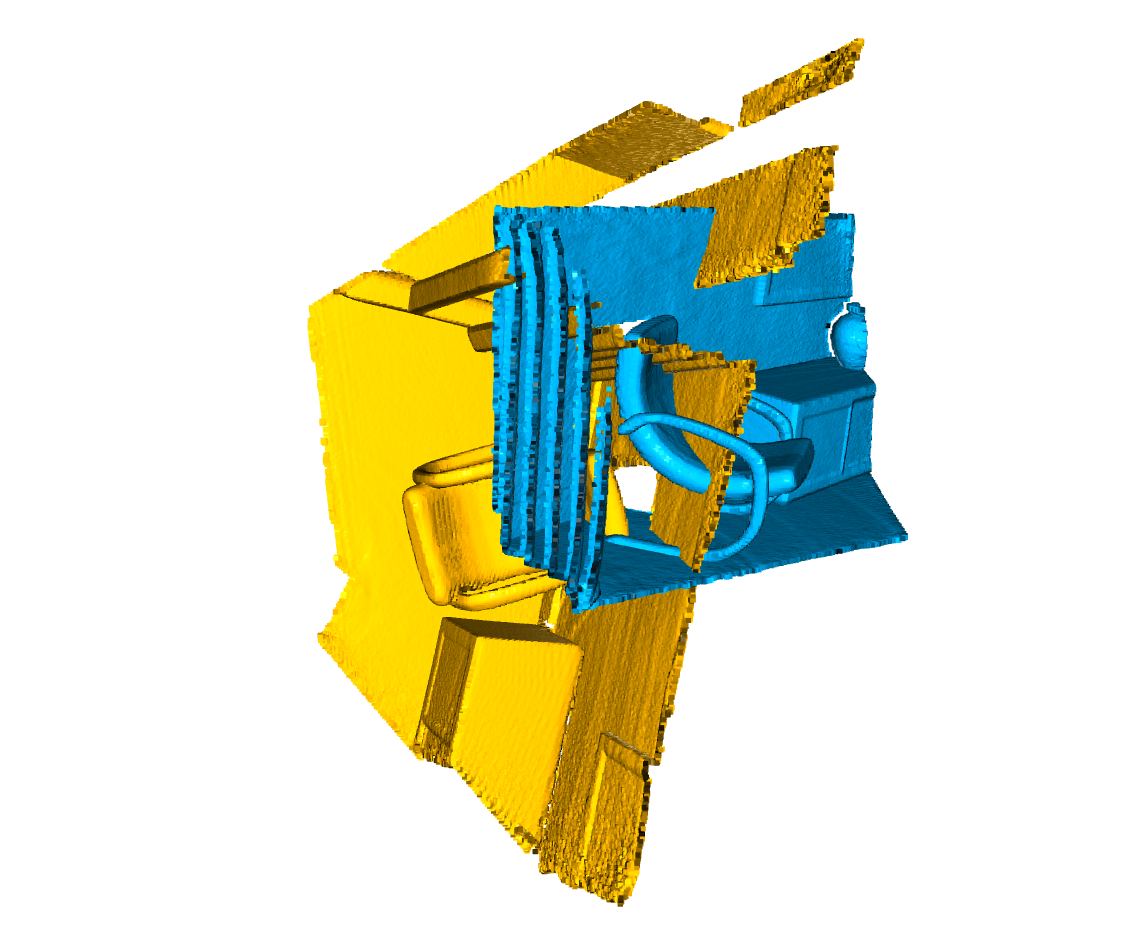

### RANSAC
We use RANSAC for global registration. In each RANSAC iteration, `ransac_n` random points are picked from the source point cloud. Their corresponding points in the target point cloud are detected by querying the nearest neighbor in the 33-dimensional FPFH feature space. A pruning step takes fast pruning algorithms to quickly reject false matches early.  
Open3D provides the following pruning algorithms:
- `CorrespondenceCheckerBasedOnDistance` checks if aligned point clouds are close (less than the specified threshold).
- `CorrespondenceCheckerBasedOnEdgeLength` checks if the lengths of any two arbitrary edges (line formed by two vertices) individually drawn from source and target correspondences are similar. This tutorial checks that

\|edge_{source}\| > 0.9 \cdot \|edge_{target}\|

  and

\|edge_{target}\| > 0.9 \cdot \|edge_{source}\|

are true.
- `CorrespondenceCheckerBasedOnNormal` considers vertex normal affinity of any correspondences. It computes the dot product of two normal vectors. It takes a radian value for the threshold.
Only matches that pass the pruning step are used to compute a transformation, which is validated on the entire point cloud. The core function is registration_ransac_based_on_feature_matching. The most important hyperparameter of this function is RANSACConvergenceCriteria. It defines the maximum number of RANSAC iterations and the confidence probability. The larger these two numbers are, the more accurate the result is, but also the more time the algorithm takes.
We set the RANSAC parameters based on the empirical value provided by [[Choi2015]](../reference.html#choi2015).

我们使用 RANSAC 进行全局配准。在 RANSAC 的每次迭代中，算法都会从源点云中随机选取`ransac_n`个点。通过在 33 维 FPFH 特征空间中搜索最近邻，找到这些点在目标点云中的对应点。随后，算法会执行一个筛选步骤，利用快速筛选算法尽早剔除错误的匹配关系。 
Open3D 提供以下筛选算法：
1. `CorrespondenceCheckerBasedOnDistance`（基于距离的对应关系检查）
检查经过变换对齐后的点云中，对应点之间的距离是否足够接近，即是否小于指定的距离阈值。
2. `CorrespondenceCheckerBasedOnEdgeLength`（基于边长的对应关系检查）
检查分别由源点云和目标点云中的对应点构成的任意两条边（由两个顶点连接形成的线段），其长度是否相似。 
本教程要求满足以下两个条件：

\|edge_{source}\| > 0.9 \cdot \|edge_{target}\|

以及

\|edge_{target}\| > 0.9 \cdot \|edge_{source}\|

也就是说，源点云和目标点云中对应边的长度比例必须处于 0.9 到约 1.111 之间，否则该对应关系将被剔除。  
3. `CorrespondenceCheckerBasedOnNormal`（基于法向量的对应关系检查）
该方法考虑对应点之间法向量方向的一致性。它通过计算两个法向量的点积，判断其方向是否相似。该方法使用以弧度（Radian）为单位的角度阈值。

只有通过筛选步骤（Pruning）的匹配关系，才会被用于计算变换矩阵。随后，算法会利用整个点云对计算得到的变换矩阵进行验证。  
该方法的核心函数是：
`registration_ransac_based_on_feature_matching`
这个函数最重要的超参数之一是：
`RANSACConvergenceCriteria`
它定义了：
- 最大 RANSAC 迭代次数（Maximum Number of RANSAC Iterations）
- 置信概率（Confidence Probability）  
这两个参数的数值越大，通常越有机会得到准确的配准结果，但算法所需要的计算时间也会增加。  
本教程根据文献 [Choi2015] 提供的经验值来设置 RANSAC 参数。